In [1]:
# =============================================================================
# 03 - EDA: storms and power outages (TRAINING YEARS 2017-2023 ONLY)
# Summary of results lives in reports/03_eda_summary.md
# Validation (2024) and test (2025) outcomes are not looked at here.
# Inputs: processed/ (from notebook 02). Figures saved to reports/figures/
# =============================================================================

In [2]:
# ---- 0. Setup ---------------------------------------------------------------
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = ROOT / "processed"
FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

TRAIN_FIRST, TRAIN_LAST = 2017, 2023
SIG_PCT = 0.01      # "significant outage" for EDA = at least 1% of county customers out (provisional)
WINDOW_HOURS = 24   # look this many hours after a storm starts

# Chart style: light surface, recessive grid, blue = storm series, gray = baseline
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#a3a29c"
INK, INK_2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "legend.frameon": False,
})


def save(fig, name):
    """Save a figure to reports/figures and show it."""
    fig.savefig(FIGS / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


con = duckdb.connect()
con.execute(f"CREATE VIEW hourly   AS SELECT * FROM read_parquet('{(PROC / 'outages_hourly').as_posix()}/*/*.parquet', hive_partitioning = true)")
con.execute(f"CREATE VIEW observed AS SELECT * FROM read_parquet('{(PROC / 'county_observed_daily.parquet').as_posix()}')")
con.execute(f"CREATE VIEW storm_county AS SELECT * FROM read_parquet('{(PROC / 'storm_county_events.parquet').as_posix()}')")
con.execute(f"CREATE VIEW counties AS SELECT * FROM read_parquet('{(PROC / 'counties.parquet').as_posix()}')")


def q(sql):
    """Run a SQL query and return a pandas DataFrame."""
    return con.execute(sql).df()

In [3]:
# ---- 1. County-days with a significant outage --------------------------------
# A county-day counts when the worst hour that day had >= 1% of customers out.
# Only days when the county was being observed (from notebook 02) are counted.
con.execute(f"""
CREATE TEMP TABLE sig_days AS
SELECT h.fips, CAST(h.hour_utc AS DATE) AS day, max(h.max_pct_out) AS peak_pct
FROM hourly h
WHERE h.year BETWEEN {TRAIN_FIRST} AND {TRAIN_LAST}
GROUP BY 1, 2
HAVING max(h.max_pct_out) >= {SIG_PCT}
""")

state_days = q(f"""
SELECT o.state_abbr                                     AS state,
       count(s.fips)                                    AS sig_outage_days,
       sum(o.observed::INT)                             AS observed_county_days,
       365.0 * count(s.fips) / sum(o.observed::INT)     AS sig_days_per_county_year
FROM observed o
LEFT JOIN sig_days s ON s.fips = o.fips AND s.day = o.day
WHERE o.year BETWEEN {TRAIN_FIRST} AND {TRAIN_LAST} AND o.observed
GROUP BY 1 HAVING sum(o.observed::INT) > 0
ORDER BY sig_outage_days DESC
""")
state_days.head(10)

,state,sig_outage_days,observed_county_days,sig_days_per_county_year
0,TX,69038,625975.0,40.255394
1,VA,36116,332386.0,39.659733
2,GA,34837,394269.0,32.250836
3,LA,26217,161076.0,59.408012
4,KY,25800,294513.0,31.974819
5,WV,22864,138781.0,60.133304
6,NC,22410,247345.0,33.069801
7,MS,21726,194587.0,40.752928
8,OH,19844,220451.0,32.855646
9,MI,19566,202942.0,35.190301


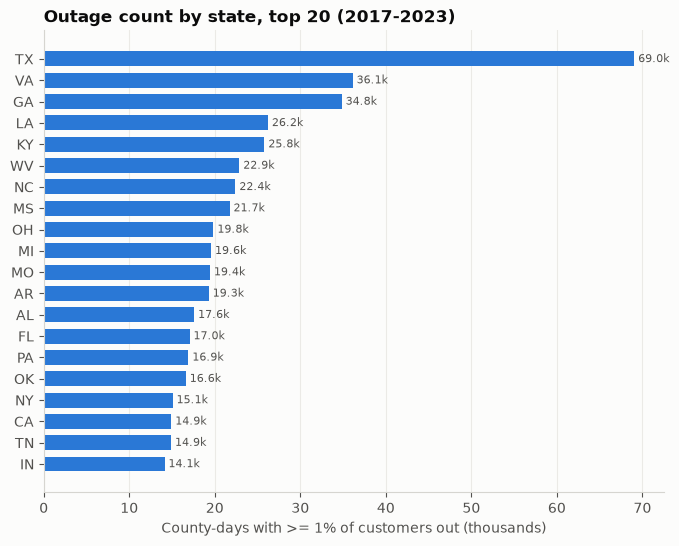

In [4]:
# ---- Figure 1: significant outage county-days by state (count) ---------------
top = state_days.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["state"], top["sig_outage_days"] / 1000, color=BLUE, height=0.7)
ax.set_xlabel("County-days with >= 1% of customers out (thousands)")
ax.set_title("Outage count by state, top 20 (2017-2023)")
ax.grid(axis="y", visible=False)
for y, v in enumerate(top["sig_outage_days"] / 1000):
    ax.text(v, y, f" {v:.1f}k", va="center", color=INK_2, fontsize=8)
save(fig, "01_outage_days_by_state")

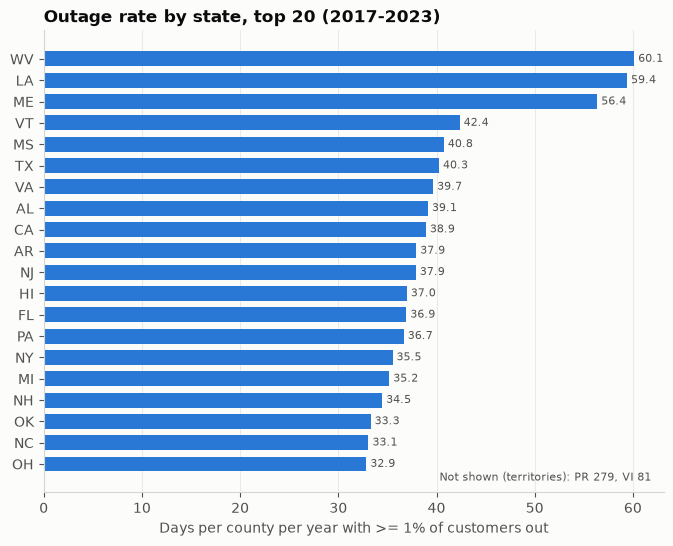

In [5]:
# ---- Figure 2: outage rate by state (per county per year) --------------------
# Counts favour states with many counties; this rate removes that effect.
# Territories (PR, VI, GU, AS) have chronic grid outages that dwarf every state,
# so they are listed in a note instead of plotted.
TERRITORIES = ["PR", "VI", "GU", "AS", "MP"]
terr = state_days[state_days["state"].isin(TERRITORIES)]
terr_note = ", ".join(f"{s} {v:.0f}" for s, v in zip(terr["state"], terr["sig_days_per_county_year"]))
top = (state_days[~state_days["state"].isin(TERRITORIES)]
       .sort_values("sig_days_per_county_year", ascending=False).head(20).iloc[::-1])
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["state"], top["sig_days_per_county_year"], color=BLUE, height=0.7)
ax.set_xlabel("Days per county per year with >= 1% of customers out")
ax.set_title("Outage rate by state, top 20 (2017-2023)")
ax.text(0.98, 0.02, f"Not shown (territories): {terr_note}", transform=ax.transAxes,
        ha="right", va="bottom", color=INK_2, fontsize=8)
ax.grid(axis="y", visible=False)
for y, v in enumerate(top["sig_days_per_county_year"]):
    ax.text(v, y, f" {v:.1f}", va="center", color=INK_2, fontsize=8)
save(fig, "02_outage_rate_by_state")

In [6]:
# ---- 3. Peak outage after each storm (per storm x county) --------------------
# For every storm-county row we take the worst hour in the 48 h after the storm starts.
# Baseline = the same county and hours exactly one week earlier (a "normal" week).
# The hourly table only has hours with an outage, so a missing hour means 0 out
# (rows are limited to counties observed on the storm's start day).
con.execute(f"""
CREATE TEMP TABLE sc AS
SELECT row_number() OVER () AS rid, event_id, fips, event_type, magnitude, magnitude_type,
       mapped_from, partial_county, date_trunc('hour', begin_utc) AS start_hr, month(begin_utc) AS month
FROM storm_county
WHERE year BETWEEN {TRAIN_FIRST} AND {TRAIN_LAST}
  AND begin_utc < TIMESTAMP '{TRAIN_LAST}-12-30'     -- keep the 48 h window inside the training years
  AND fips_known AND county_observed_on_begin_day
""")
peaks = q(f"""
WITH hours AS (
    SELECT rid, fips, start_hr + to_hours(h) AS hr, h
    FROM sc CROSS JOIN range(0, 48) t(h)
),
after AS (
    SELECT x.rid,
           max(o.max_pct_out) FILTER (WHERE x.h < {WINDOW_HOURS}) AS peak_24h,
           max(o.max_pct_out)                                     AS peak_48h,
           arg_max(x.h, o.max_pct_out)                            AS hour_of_peak
    FROM hours x JOIN hourly o ON o.fips = x.fips AND o.hour_utc = x.hr
    WHERE o.year BETWEEN {TRAIN_FIRST} AND {TRAIN_LAST}
    GROUP BY x.rid
),
before AS (
    SELECT x.rid, max(o.max_pct_out) AS baseline_24h
    FROM hours x JOIN hourly o ON o.fips = x.fips AND o.hour_utc = x.hr - INTERVAL 7 DAY
    WHERE x.h < {WINDOW_HOURS} AND o.year BETWEEN {TRAIN_FIRST} AND {TRAIN_LAST}
    GROUP BY x.rid
)
SELECT sc.*,
       coalesce(a.peak_24h, 0)     AS peak_24h,
       coalesce(a.peak_48h, 0)     AS peak_48h,
       a.hour_of_peak,
       coalesce(b.baseline_24h, 0) AS baseline_24h
FROM sc LEFT JOIN after a USING (rid) LEFT JOIN before b USING (rid)
""")
peaks["outage"] = peaks["peak_24h"] >= SIG_PCT
peaks["baseline_outage"] = peaks["baseline_24h"] >= SIG_PCT
print(f"{len(peaks):,} storm-county rows | {peaks['outage'].mean():.1%} had >= 1% out within 24 h "
      f"| baseline week {peaks['baseline_outage'].mean():.1%}")

by_type = (peaks.groupby("event_type")
           .agg(rows=("rid", "count"), outages=("outage", "sum"),
                outage_rate=("outage", "mean"), baseline_rate=("baseline_outage", "mean"),
                median_peak=("peak_24h", "median"))
           .sort_values("outages", ascending=False))
by_type.head(20)

452,668 storm-county rows | 35.2% had >= 1% out within 24 h | baseline week 8.3%


,rows,outages,outage_rate,baseline_rate,median_peak
event_type,,,,,
Thunderstorm Wind,118448,73535,0.620821,0.097325,0.019216
Hail,54787,18079,0.329987,0.074288,0.002720
High Wind,34810,10316,0.296352,0.057857,0.001055
Flash Flood,25646,10314,0.402168,0.105475,0.006085
Tornado,9804,5897,0.601489,0.083129,0.021713
Winter Storm,23804,5345,0.224542,0.061502,0.000275
Flood,20276,5286,0.260702,0.090353,0.001867
Heavy Snow,23451,4947,0.210950,0.068142,0.000341
Strong Wind,9421,4287,0.455047,0.086721,0.007420


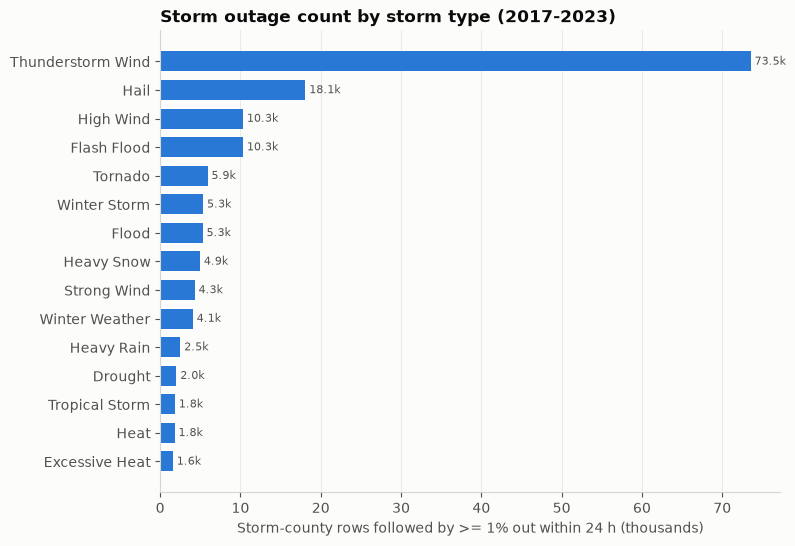

In [7]:
# ---- Figure 3: storm-related outage count by storm type -----------------------
top = by_type.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top["outages"] / 1000, color=BLUE, height=0.7)
ax.set_xlabel("Storm-county rows followed by >= 1% out within 24 h (thousands)")
ax.set_title("Storm outage count by storm type (2017-2023)")
ax.grid(axis="y", visible=False)
for y, v in enumerate(top["outages"] / 1000):
    ax.text(v, y, f" {v:.1f}k", va="center", color=INK_2, fontsize=8)
save(fig, "03_storm_outage_count_by_type")

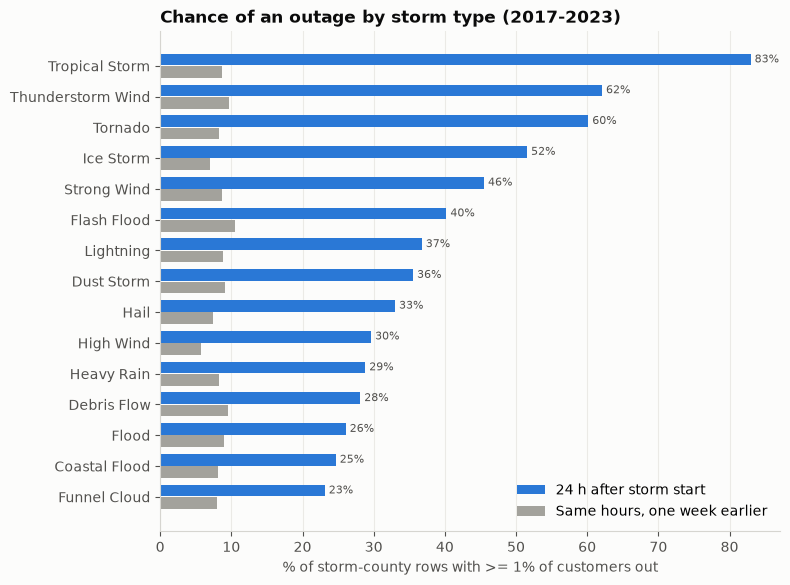

In [8]:
# ---- Figure 4: outage probability by storm type vs a normal week --------------
# Only storm types with at least 500 storm-county rows, so rates are stable.
rate = by_type[by_type["rows"] >= 500].sort_values("outage_rate").tail(15)
y = np.arange(len(rate))
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(y + 0.2, rate["outage_rate"] * 100, height=0.38, color=BLUE, label="24 h after storm start")
ax.barh(y - 0.2, rate["baseline_rate"] * 100, height=0.38, color=GRAY, label="Same hours, one week earlier")
ax.set_yticks(y, rate.index)
ax.set_xlabel("% of storm-county rows with >= 1% of customers out")
ax.set_title("Chance of an outage by storm type (2017-2023)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
for yy, v in zip(y, rate["outage_rate"] * 100):
    ax.text(v, yy + 0.2, f" {v:.0f}%", va="center", color=INK_2, fontsize=8)
save(fig, "04_outage_probability_by_type")

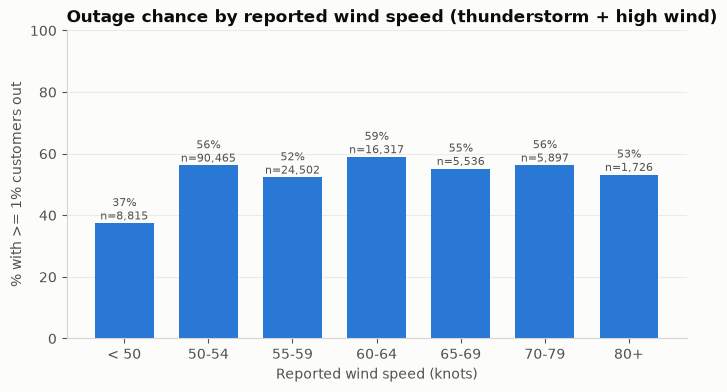

,rows,outage_rate
speed_bin,,
< 50,8815,0.374248
50-54,90465,0.561897
55-59,24502,0.523059
60-64,16317,0.589447
65-69,5536,0.551301
70-79,5897,0.562320
80+,1726,0.531866


In [9]:
# ---- Figure 5: wind speed vs outage probability -------------------------------
# Thunderstorm and high wind events report wind speed in knots.
wind = peaks[peaks["event_type"].isin(["Thunderstorm Wind", "High Wind"]) & peaks["magnitude"].notna()].copy()
bins = [0, 50, 55, 60, 65, 70, 80, 200]
labels = ["< 50", "50-54", "55-59", "60-64", "65-69", "70-79", "80+"]
wind["speed_bin"] = pd.cut(wind["magnitude"], bins=bins, labels=labels, right=False)
wind_rate = wind.groupby("speed_bin", observed=True).agg(rows=("rid", "count"), outage_rate=("outage", "mean"))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(wind_rate.index.astype(str), wind_rate["outage_rate"] * 100, color=BLUE, width=0.7)
ax.set_xlabel("Reported wind speed (knots)")
ax.set_ylabel("% with >= 1% customers out")
ax.set_title("Outage chance by reported wind speed (thunderstorm + high wind)")
ax.grid(axis="x", visible=False)
for x, (v, n) in enumerate(zip(wind_rate["outage_rate"] * 100, wind_rate["rows"])):
    ax.text(x, v, f"{v:.0f}%\nn={n:,}", ha="center", va="bottom", color=INK_2, fontsize=8)
ax.set_ylim(0, 100)
save(fig, "05_wind_speed_vs_outage")
wind_rate

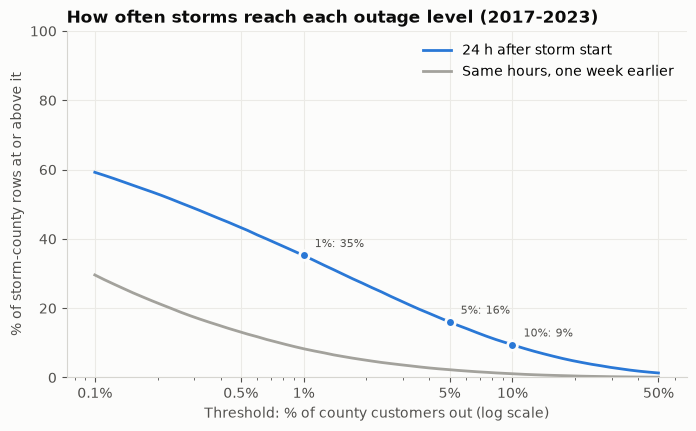

In [10]:
# ---- Figure 6: how severe are storm outages? (exceedance curve) ---------------
# For each threshold X: share of storm-county rows whose 24 h peak reached X% out.
# This shows how the target threshold choice changes the positive rate.
thresholds = np.logspace(-3, np.log10(0.5), 60)
storm_curve = [(peaks["peak_24h"] >= t).mean() * 100 for t in thresholds]
base_curve = [(peaks["baseline_24h"] >= t).mean() * 100 for t in thresholds]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thresholds * 100, storm_curve, color=BLUE, linewidth=2, label="24 h after storm start")
ax.plot(thresholds * 100, base_curve, color=GRAY, linewidth=2, label="Same hours, one week earlier")
ax.set_xscale("log")
ax.set_xticks([0.1, 0.5, 1, 5, 10, 50], ["0.1%", "0.5%", "1%", "5%", "10%", "50%"])
ax.set_xlabel("Threshold: % of county customers out (log scale)")
ax.set_ylabel("% of storm-county rows at or above it")
ax.set_title("How often storms reach each outage level (2017-2023)")
for t in [0.01, 0.05, 0.10]:
    v = (peaks["peak_24h"] >= t).mean() * 100
    ax.plot(t * 100, v, "o", color=BLUE, markersize=7, markeredgecolor="#fcfcfb", markeredgewidth=2)
    ax.annotate(f"{t:.0%}: {v:.0f}%", (t * 100, v), textcoords="offset points", xytext=(8, 6), color=INK_2, fontsize=8)
ax.legend(loc="upper right")
ax.set_ylim(0, 100)
save(fig, "06_outage_severity_exceedance")

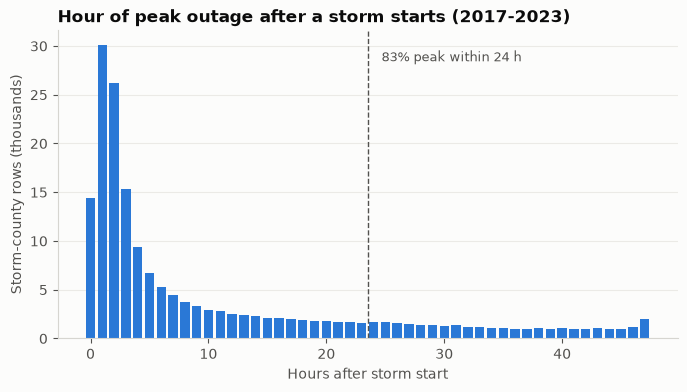

median hour of peak: 4 | within 6 h: 57%


In [11]:
# ---- Figure 7: when does the outage peak after a storm starts? ----------------
# Rows that reached >= 1% within 48 h; the hour (0-47) of their worst reading.
hit = peaks[peaks["peak_48h"] >= SIG_PCT]
fig, ax = plt.subplots(figsize=(8, 4))
counts = hit["hour_of_peak"].value_counts().sort_index()
ax.bar(counts.index, counts.values / 1000, color=BLUE, width=0.8)
ax.axvline(WINDOW_HOURS - 0.5, color=INK_2, linestyle="--", linewidth=1)
share_24 = (hit["hour_of_peak"] < WINDOW_HOURS).mean()
ax.text(WINDOW_HOURS, ax.get_ylim()[1] * 0.9, f"  {share_24:.0%} peak within 24 h", color=INK_2, fontsize=9)
ax.set_xlabel("Hours after storm start")
ax.set_ylabel("Storm-county rows (thousands)")
ax.set_title("Hour of peak outage after a storm starts (2017-2023)")
ax.grid(axis="x", visible=False)
save(fig, "07_hours_to_peak")
print(f"median hour of peak: {hit['hour_of_peak'].median():.0f} | within 6 h: {(hit['hour_of_peak'] < 6).mean():.0%}")

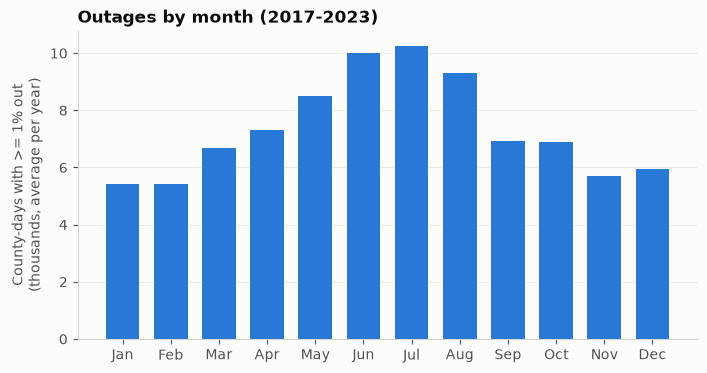

,rows,outage_rate
Jan,40870,0.224468
Feb,39643,0.217315
Mar,36949,0.311835
Apr,39577,0.385931
May,44234,0.413189
Jun,54087,0.467210
Jul,56267,0.415785
Aug,46283,0.406110
Sep,21977,0.357419
Oct,20218,0.321496


In [12]:
# ---- Figure 8: seasonality -----------------------------------------------------
# Significant outage county-days per month vs the storm-related outage rate per month.
monthly = q("SELECT month(day) AS month, count(*) / 7.0 AS sig_days_per_year FROM sig_days GROUP BY 1 ORDER BY 1")
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(month_names, monthly["sig_days_per_year"] / 1000, color=BLUE, width=0.7)
ax.set_ylabel("County-days with >= 1% out\n(thousands, average per year)")
ax.set_title("Outages by month (2017-2023)")
ax.grid(axis="x", visible=False)
save(fig, "08_outages_by_month")

storm_month = peaks.groupby("month").agg(rows=("rid", "count"), outage_rate=("outage", "mean"))
storm_month.index = month_names
storm_month

In [13]:
# ---- 9. Extra numbers for the summary -----------------------------------------
# Zone-coded vs county-coded storms, and partial-county zones
print(peaks.groupby(["mapped_from", "partial_county"])["outage"].agg(["count", "mean"]).round(3))

# How many significant outage days happen with NO storm record nearby?
q(f"""
WITH storm_days AS (
    SELECT DISTINCT fips, CAST(CAST(begin_utc AS DATE) + to_days(CAST(d AS INT)) AS DATE) AS day
    FROM storm_county CROSS JOIN range(-1, 2) t(d)       -- storm day +/- 1 day
    WHERE year BETWEEN {TRAIN_FIRST} AND {TRAIN_LAST}
)
SELECT count(*) AS sig_outage_days,
       round(100 * avg((sd.fips IS NOT NULL)::INT), 1)                    AS pct_with_storm_record,
       round(100 * avg((sd.fips IS NOT NULL)::INT) FILTER (WHERE peak_pct >= 0.10), 1) AS pct_with_storm_if_10pct_out
FROM sig_days s LEFT JOIN storm_days sd USING (fips, day)
""")

                             count   mean
mapped_from partial_county               
county      False           242305  0.483
zone        False            96373  0.210
            True            113990  0.195


,sig_outage_days,pct_with_storm_record,pct_with_storm_if_10pct_out
0,618429,20.6,32.1


In [14]:
con.close()